# Saved clone-trajectory embeddings for the Weinreb and Singh supplementary figures

## Scope
Produce two independent, editable raw panels from the saved clone-coordinate registries. One point is one retained LARRY clone (Weinreb) or resolved clonal family (Singh), never one cell. No graph, UMAP, partition, expression model, or statistical test is refitted. Original point order and coordinate values are preserved. Dataset-specific metaclone palettes follow the current manuscript references; metaclone numbers are not matched entities across datasets.

The Weinreb geometry is the previously approved, locked trajectory-space display constructed from historical working-state features. The source feature names are retained in the provenance table, not interpreted as separate HSPC biological compartments. Current biological interpretation pools HSPCs. The two UMAP coordinate systems are independent and their distances are not comparable across datasets. These displays summarize reference trajectories used in grouping, not independent validation.

## Environment and execution
Existing local environment manager: Conda (pre-existing environment, reused without installation or mutation). Environment: **chronoclone**. Absolute MacBook path: `/path/to/ChronoClone/.runtime/chronoclone`. Kernel: `chronoclone`. Versions are reported by the setup cell.

Rebuild notebook:
```
/path/to/ChronoClone/.runtime/chronoclone/bin/python /path/to/ChronoClone/analysis_workspace/weinreb/weinreb_singh_clone_umap_comparison_20260911/build_notebook.py
```

Execute:
```
IPYTHONDIR=/private/tmp/chronoclone-clone-umap-ipython JUPYTER_RUNTIME_DIR=/private/tmp/chronoclone-clone-umap-runtime MPLCONFIGDIR=/private/tmp/chronoclone-clone-umap-mpl /path/to/ChronoClone/.runtime/chronoclone/bin/python /path/to/ChronoClone/analysis_workspace/weinreb/weinreb_singh_clone_umap_comparison_20260911/execute_notebook.py
```


In [1]:
from pathlib import Path
import sys,json,hashlib,platform,re
from importlib.metadata import version
from datetime import datetime,timezone
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import anndata as ad
import nbformat,nbclient
from IPython.display import display
ROOT=Path('/path/to/ChronoClone')
OUT=ROOT/'analysis_workspace/weinreb/weinreb_singh_clone_umap_comparison_20260911'
for name in ['panels','tables','reports']:
    (OUT/name).mkdir(parents=True,exist_ok=True)
assert sys.prefix=='/path/to/ChronoClone/.runtime/chronoclone'
versions={'environment_manager':'existing Conda environment','environment':'chronoclone','environment_path':sys.prefix,'kernel':'chronoclone','Python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'anndata':version('anndata'),'nbformat':nbformat.__version__,'nbclient':nbclient.__version__}
(OUT/'reports/environment.json').write_text(json.dumps(versions,indent=2)+'\n')
display(versions)
plt.rcParams.update({'svg.fonttype':'none','font.family':'DejaVu Sans','font.size':14,'axes.labelsize':16,'axes.edgecolor':'#17324D','axes.labelcolor':'#17324D','figure.facecolor':'white'})
sha=lambda p:hashlib.sha256(Path(p).read_bytes()).hexdigest()
WEIN=ROOT/'analysis_workspace/weinreb/weinreb_clone_trajectory_umap_20260810'
SINGH=ROOT/'analysis_workspace/singh/figure3_original_singh_landscape_20260811'
RUN=ROOT/'analysis_workspace/singh/singh_reference_response_20260911'
w_geometry_path=WEIN/'tables/weinreb_clone_trajectory_umap_locked_geometry.csv'
w_source_path=WEIN/'tables/weinreb_clone_trajectory_umap_metaclone_labeled_source.csv'
w_labels_path=WEIN/'tables/weinreb_clone_trajectory_umap_metaclone_label_positions.csv'
w_features_path=WEIN/'tables/weinreb_clone_trajectory_feature_matrix.csv'
s_geometry_path=ROOT/'analysis_workspace/final_release/source_tables/figure3/fig3c_full_trajectory_embedding.csv'
s_labels_path=SINGH/'tables/figure3_original_singh_clone_trajectory_umap_metaclone_label_positions.csv'
s_features_path=ROOT/'analysis_workspace/final_release/source_tables/figure3/fig3c_clone_trajectory_feature_matrix.csv'
s_registry_path=RUN/'dynamics/tables/lineage_family_registry.csv'
w_author_path=ROOT/'data/interim/klein/20260724_reference_rebuild/source/klein_metaclone.h5ad'
sources=[w_geometry_path,w_source_path,w_labels_path,w_features_path,s_geometry_path,s_labels_path,s_features_path,s_registry_path,w_author_path,WEIN/'tables/weinreb_clone_trajectory_umap_parameters.csv',SINGH/'tables/figure3_original_singh_clone_trajectory_umap_parameters.csv']
manifest=[{'path':str(p.relative_to(ROOT)),'bytes':p.stat().st_size,'sha256':sha(p),'access':'read-only'} for p in sources]
pd.DataFrame(manifest).to_csv(OUT/'reports/source_manifest.csv',index=False)
display(pd.DataFrame(manifest)[['path','sha256']])


{'environment_manager': 'existing Conda environment',
 'environment': 'chronoclone',
 'environment_path': '/path/to/ChronoClone/.runtime/chronoclone',
 'kernel': 'chronoclone',
 'Python': '3.11.15',
 'numpy': '2.4.6',
 'pandas': '2.3.3',
 'matplotlib': '3.11.0',
 'anndata': '0.12.18',
 'nbformat': '5.10.4',
 'nbclient': '0.11.0'}

,path,sha256
0,analysis_workspace/weinreb/weinreb_clone_trajectory...,fb63c00d895b11c0602d1e7a733d22a97bfa8ef80af12a...
1,analysis_workspace/weinreb/weinreb_clone_trajectory...,a04f0f116436283fb1ce32488d060ab6abe5d2abb20357...
2,analysis_workspace/weinreb/weinreb_clone_trajectory...,b9508e8cd7a5cada87eeada5edccabfa7fa56403ec6d01...
3,analysis_workspace/weinreb/weinreb_clone_trajectory...,f6dd8438799b7dd355300ad79cca48668f5cdb9f2109f9...
4,analysis_workspace/final_release/source_tables/figu...,f9cc8835c64adce092dbc8018793a7bcf7e8ae584bda77...
5,analysis_workspace/singh/figure3_original_singh_lan...,df1b27dc2c3440de24f4c345764d2da73a2bece5a461d9...
6,analysis_workspace/final_release/source_tables/figu...,85128c9d5177f98228b976a5e6445fb4792b913c294dda...
7,analysis_workspace/singh/singh_reference_response_2...,735fcbed86958ece0bcc1e6e5d142f992be559000cdac8...
8,data/interim/klein/20260724_reference_rebuild/sou...,cd2b9e3c986c80c4c3394fb8ad9e6ef4cdf376ba88e94b...
9,analysis_workspace/weinreb/weinreb_clone_trajectory...,591a3314fbf4b4f0fd5268cbe75fc85156213ff9656521...


## Verify the saved clone registries and feature provenance

In [2]:
W=pd.read_csv(w_source_path)
WG=pd.read_csv(w_geometry_path)
WF=pd.read_csv(w_features_path,index_col='LARRY_ID')
WL=pd.read_csv(w_labels_path).set_index('metaclone')
S=pd.read_csv(s_geometry_path)
SF=pd.read_csv(s_features_path).set_index('clone_id')
SL=pd.read_csv(s_labels_path).set_index('metaclone')
SR=pd.read_csv(s_registry_path)
assert sha(w_geometry_path)=='fb63c00d895b11c0602d1e7a733d22a97bfa8ef80af12a9ffa1e2e1f3575012f'
assert W.LARRY_ID.is_unique and S.clone_id.is_unique
assert W.LARRY_ID.tolist()==WG.LARRY_ID.tolist()==WF.index.tolist()
assert np.array_equal(W[['UMAP1','UMAP2']].to_numpy(),WG[['UMAP1','UMAP2']].to_numpy())
assert S.clone_id.tolist()==SF.index.tolist()
assert set(S.clone_id)==set(SR.clone)
assert S.set_index('clone_id').metaclone.sort_index().equals(SR.set_index('clone').mc.sort_index())
w_author=ad.read_h5ad(w_author_path,backed='r')
wo=w_author.obs[['LARRY_ID','metaclone']].copy()
w_author.file.close()
wo=wo.loc[wo.metaclone.astype(int).ne(-1)]
assert wo.groupby('LARRY_ID',observed=True).metaclone.nunique().max()==1
w_registry=wo.groupby('LARRY_ID',observed=True).metaclone.first().astype(int)
assert set(W.LARRY_ID)==set(w_registry.index)
assert np.array_equal(W.metaclone.to_numpy(),w_registry.reindex(W.LARRY_ID).to_numpy())
assert len(W)==569 and W.metaclone.nunique()==20 and WF.shape[1]==44
s_feature_columns=[c for c in SF if c.startswith(('D7:','D14:','D27:'))]
assert len(S)==1516 and S.metaclone.nunique()==17 and len(s_feature_columns)==21
assert np.isfinite(W[['UMAP1','UMAP2']].to_numpy()).all() and np.isfinite(S[['UMAP1','UMAP2']].to_numpy()).all()
assert set(W.metaclone)==set(WL.index) and set(S.metaclone)==set(SL.index)
w_palette=W.groupby('metaclone').point_color.first().to_dict()
assert W.groupby('metaclone').point_color.nunique().eq(1).all()
s_palette=SL.label_color.to_dict()
assert s_palette=={0:'#f77189',1:'#f8763b',2:'#d28e32',3:'#b79932',4:'#9ea231',5:'#7caa31',6:'#31b345',7:'#34b081',9:'#35ae9a',10:'#36acad',11:'#38aac1',12:'#3aa6dd',13:'#7699f4',15:'#b087f4',16:'#df6df4',17:'#f563d8',19:'#f66ab2'}
pd.concat([W.groupby('metaclone').size().rename('clones').reset_index().assign(dataset='Weinreb'),S.groupby('metaclone').size().rename('clones').reset_index().assign(dataset='Singh')],ignore_index=True).to_csv(OUT/'tables/metaclone_clone_counts.csv',index=False)
feature_registry=pd.concat([pd.DataFrame({'dataset':'Weinreb','source_feature':WF.columns,'role':'historical saved geometry; not a new biological subgroup analysis'}),pd.DataFrame({'dataset':'Singh','source_feature':s_feature_columns,'role':'WT clone composition at the three reference snapshots'})],ignore_index=True)
feature_registry.to_csv(OUT/'tables/embedding_feature_registry.csv',index=False)
cohort=pd.DataFrame([{'dataset':'Weinreb','points':len(W),'metaclones':W.metaclone.nunique(),'feature_columns':WF.shape[1],'geometry':'locked saved coordinates','registry_verified':True,'new_fit':False},{'dataset':'Singh','points':len(S),'metaclones':S.metaclone.nunique(),'feature_columns':len(s_feature_columns),'geometry':'locked saved coordinates','registry_verified':True,'new_fit':False}])
cohort.to_csv(OUT/'reports/cohort_geometry_checks.csv',index=False)
display(cohort)
print('Original coordinate values and point order preserved; all clone IDs reconcile to current retained registries.')


,dataset,points,metaclones,feature_columns,geometry,registry_verified,new_fit
0,Weinreb,569,20,44,locked saved coordinates,True,False
1,Singh,1516,17,21,locked saved coordinates,True,False


Original coordinate values and point order preserved; all clone IDs reconcile to current retained registries.


## Weinreb: one point per retained LARRY clone

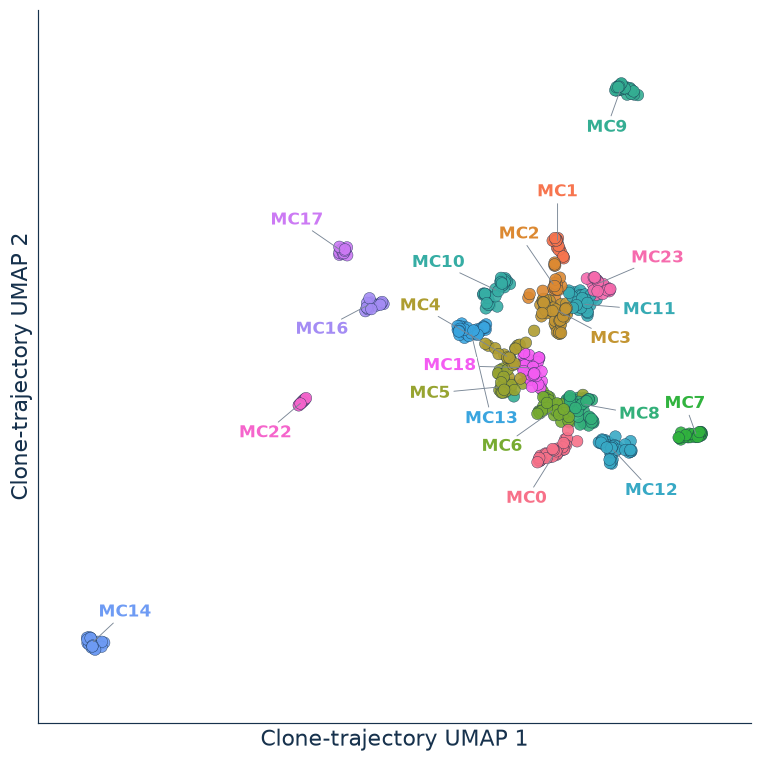

/path/to/ChronoClone/analysis_workspace/weinreb/weinreb_singh_clone_umap_comparison_20260911/panels/weinreb_clone_trajectory_umap.svg
{'label_bbox_overlaps': np.int64(0), 'clones': 569}


In [3]:
# Plot-specific shaping, full construction, export and display are inline in this cell.
plot=W[['point_order','LARRY_ID','UMAP1','UMAP2','metaclone']].copy()
plot['point_color']=plot.metaclone.map(w_palette)
labels=WL.loc[sorted(plot.metaclone.unique())].copy()
assert plot.LARRY_ID.tolist()==WG.LARRY_ID.tolist()
assert np.array_equal(plot[['UMAP1','UMAP2']].to_numpy(),WG[['UMAP1','UMAP2']].to_numpy())
fig,ax=plt.subplots(figsize=(7.8,7.8))
ax.scatter(plot.UMAP1,plot.UMAP2,c=plot.point_color,s=70,alpha=.90,edgecolors='#17324D',linewidths=.30,marker='o',rasterized=False,clip_on=False,zorder=2)
annotations=[]
for mc,row in labels.iterrows():
    annotations.append(ax.annotate(f'MC{mc}',xy=(row.anchor_UMAP1,row.anchor_UMAP2),xytext=(row.label_UMAP1,row.label_UMAP2),textcoords='data',ha='center',va='center',fontsize=12,fontweight='bold',color=w_palette[mc],arrowprops={'arrowstyle':'-','lw':.65,'color':'#7A8796'},bbox={'facecolor':'white','edgecolor':'none','pad':.5},annotation_clip=False,zorder=3))
all_x=np.r_[plot.UMAP1,labels.label_UMAP1];all_y=np.r_[plot.UMAP2,labels.label_UMAP2]
center_x=(all_x.max()+all_x.min())/2;center_y=(all_y.max()+all_y.min())/2
span=max(np.ptp(all_x),np.ptp(all_y))*1.16
ax.set_xlim(center_x-span/2,center_x+span/2);ax.set_ylim(center_y-span/2,center_y+span/2)
ax.set_aspect('equal',adjustable='box')
ax.set(xticks=[],yticks=[],xlabel='Clone-trajectory UMAP 1',ylabel='Clone-trajectory UMAP 2')
for side in ['top','right']:ax.spines[side].set_visible(False)
for side in ['left','bottom']:ax.spines[side].set_linewidth(.85)
fig.tight_layout(pad=1.0);fig.canvas.draw()
renderer=fig.canvas.get_renderer()
text_boxes=[matplotlib.text.Text.get_window_extent(a,renderer) for a in annotations]
overlaps=sum(text_boxes[i].overlaps(text_boxes[j]) for i in range(len(text_boxes)) for j in range(i+1,len(text_boxes)))
stem=OUT/'panels/weinreb_clone_trajectory_umap'
fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight',pad_inches=.10)
fig.savefig(stem.with_suffix('.png'),dpi=320,bbox_inches='tight',pad_inches=.10)
plot.to_csv(OUT/'tables/weinreb_clone_umap_plot_data.csv',index=False)
pd.DataFrame([{'panel':stem.name,'one_point_per_clone':len(ax.collections[0].get_offsets())==len(plot),'labels':len(annotations),'label_bbox_overlaps':overlaps,'saved_geometry_exact':True,'no_refit':True}]).to_csv(OUT/'reports/weinreb_plot_checks.csv',index=False)
display(fig);plt.close(fig);print(stem.with_suffix('.svg'));print({'label_bbox_overlaps':overlaps,'clones':len(plot)})


## Singh: one point per resolved clonal family

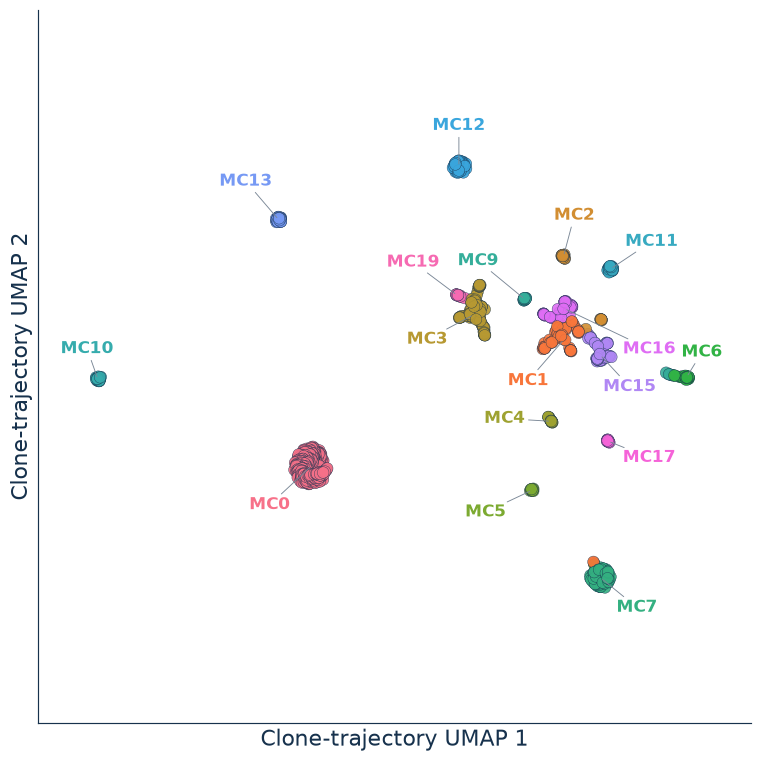

/path/to/ChronoClone/analysis_workspace/weinreb/weinreb_singh_clone_umap_comparison_20260911/panels/singh_clone_trajectory_umap.svg
{'label_bbox_overlaps': np.int64(0), 'clones': 1516}


In [4]:
# Plot-specific shaping, full construction, export and display are inline in this cell.
plot=S[['clone_id','UMAP1','UMAP2','metaclone']].copy()
plot['point_color']=plot.metaclone.map(s_palette)
labels=SL.loc[sorted(plot.metaclone.unique())].copy()
assert plot.clone_id.tolist()==S.clone_id.tolist()
assert np.array_equal(plot[['UMAP1','UMAP2']].to_numpy(),S[['UMAP1','UMAP2']].to_numpy())
fig,ax=plt.subplots(figsize=(7.8,7.8))
ax.scatter(plot.UMAP1,plot.UMAP2,c=plot.point_color,s=70,alpha=.90,edgecolors='#17324D',linewidths=.30,marker='o',rasterized=False,clip_on=False,zorder=2)
annotations=[]
for mc,row in labels.iterrows():
    annotations.append(ax.annotate(f'MC{mc}',xy=(row.anchor_UMAP1,row.anchor_UMAP2),xytext=(row.label_UMAP1,row.label_UMAP2),textcoords='data',ha='center',va='center',fontsize=12,fontweight='bold',color=s_palette[mc],arrowprops={'arrowstyle':'-','lw':.65,'color':'#7A8796'},bbox={'facecolor':'white','edgecolor':'none','pad':.5},annotation_clip=False,zorder=3))
all_x=np.r_[plot.UMAP1,labels.label_UMAP1];all_y=np.r_[plot.UMAP2,labels.label_UMAP2]
center_x=(all_x.max()+all_x.min())/2;center_y=(all_y.max()+all_y.min())/2
span=max(np.ptp(all_x),np.ptp(all_y))*1.16
ax.set_xlim(center_x-span/2,center_x+span/2);ax.set_ylim(center_y-span/2,center_y+span/2)
ax.set_aspect('equal',adjustable='box')
ax.set(xticks=[],yticks=[],xlabel='Clone-trajectory UMAP 1',ylabel='Clone-trajectory UMAP 2')
for side in ['top','right']:ax.spines[side].set_visible(False)
for side in ['left','bottom']:ax.spines[side].set_linewidth(.85)
fig.tight_layout(pad=1.0);fig.canvas.draw()
renderer=fig.canvas.get_renderer()
text_boxes=[matplotlib.text.Text.get_window_extent(a,renderer) for a in annotations]
overlaps=sum(text_boxes[i].overlaps(text_boxes[j]) for i in range(len(text_boxes)) for j in range(i+1,len(text_boxes)))
stem=OUT/'panels/singh_clone_trajectory_umap'
fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight',pad_inches=.10)
fig.savefig(stem.with_suffix('.png'),dpi=320,bbox_inches='tight',pad_inches=.10)
plot.to_csv(OUT/'tables/singh_clone_umap_plot_data.csv',index=False)
pd.DataFrame([{'panel':stem.name,'one_point_per_clone':len(ax.collections[0].get_offsets())==len(plot),'labels':len(annotations),'label_bbox_overlaps':overlaps,'saved_geometry_exact':True,'no_refit':True}]).to_csv(OUT/'reports/singh_plot_checks.csv',index=False)
display(fig);plt.close(fig);print(stem.with_suffix('.svg'));print({'label_bbox_overlaps':overlaps,'clones':len(plot)})


## Artifact checks and caption provenance

In [5]:
import xml.etree.ElementTree as ET
checks=pd.concat([pd.read_csv(OUT/'reports/weinreb_plot_checks.csv'),pd.read_csv(OUT/'reports/singh_plot_checks.csv')],ignore_index=True)
assert checks.one_point_per_clone.all() and checks.saved_geometry_exact.all() and checks.no_refit.all()
assert checks.label_bbox_overlaps.eq(0).all(),checks
svg_rows=[]
for dataset,expected in [('weinreb',set(W.metaclone)),('singh',set(S.metaclone))]:
    p=OUT/'panels'/f'{dataset}_clone_trajectory_umap.svg'
    tree=ET.parse(p)
    nodes=list(tree.iter())
    texts=[''.join(x.itertext()) for x in nodes if x.tag.endswith('}text')]
    assert not any(x.tag.endswith('}image') for x in nodes),'Clone marks must remain vectors'
    assert all(f'MC{mc}' in texts for mc in expected)
    svg_rows.append({'file':str(p.relative_to(ROOT)),'sha256':sha(p),'live_svg_text':True,'all_mc_labels':True,'embedded_raster_images':0})
pd.DataFrame(svg_rows).to_csv(OUT/'reports/svg_checks.csv',index=False)
for r in manifest:
    assert sha(ROOT/r['path'])==r['sha256'],'Source changed during notebook execution'
caption_rows=[
 {'panel':'weinreb_clone_trajectory_umap','caption':f'Weinreb clone-trajectory embedding. Each point represents one of {len(W):,} retained LARRY clones, colored by its ChronoClone metaclone ({W.metaclone.nunique()} groups). The original locked UMAP coordinates summarize normalized clone-by-time-by-working-state profiles across Days 2, 4, and 6. This retrospective reference-space visualization is distinct from the single-cell landscape and is not independent evidence of cluster recovery.'},
 {'panel':'singh_clone_trajectory_umap','caption':f'Singh WT clone-trajectory embedding. Each point represents one of {len(S):,} resolved clonal families, colored by its fixed WT-reference metaclone ({S.metaclone.nunique()} groups). The preserved embedding summarizes WT compositions in seven cell categories at Days 7, 14, and 27, with HSPCs represented as one category. No mutant data are required to place these reference points. The coordinates are independent of the Weinreb embedding and cannot be compared across datasets.'}]
pd.DataFrame(caption_rows).to_csv(OUT/'tables/caption_wording.csv',index=False)
visual_review=[{'panel':'weinreb_clone_trajectory_umap','png_sha256':'6f0ece8999f726a0eafc8a9c3bc638c2b35246c17f6a1b021398b88e35f1b83c','verdict':'pass','observed':'Individually viewed at full panel size: 20 readable MC labels, clear leader lines, no clipped circles or overlapping label text. Saved asymmetric geometry retained.'},{'panel':'singh_clone_trajectory_umap','png_sha256':'47873c10b5a8ef248c0914923260504a09eba07e91f6d50eafaaebfad814c474','verdict':'pass','observed':'Individually viewed at full panel size: 17 readable MC labels, no clipping or label collisions. Dense MC0 marks overlap as expected from unchanged coordinates; no points were removed.'}]
for r in visual_review:
    assert sha(OUT/'panels'/f"{r['panel']}.png")==r['png_sha256'],'Panel changed since its individual visual review'
pd.DataFrame(visual_review).to_csv(OUT/'reports/individual_visual_review.csv',index=False)
artifacts=[]
for folder in ['panels','tables','reports']:
    for p in sorted((OUT/folder).glob('*')):
        if p.is_file() and p.name!='artifact_manifest.csv':
            artifacts.append({'path':str(p.relative_to(ROOT)),'bytes':p.stat().st_size,'sha256':sha(p)})
pd.DataFrame(artifacts).to_csv(OUT/'reports/artifact_manifest.csv',index=False)
display(checks);display(pd.DataFrame(caption_rows));display(pd.DataFrame(visual_review))
print('Numerical and SVG checks passed. Both separate PNGs retain the exact hashes of their individual visual inspections.')


,panel,one_point_per_clone,labels,label_bbox_overlaps,saved_geometry_exact,no_refit
0,weinreb_clone_trajectory_umap,True,20,0,True,True
1,singh_clone_trajectory_umap,True,17,0,True,True


,panel,caption
0,weinreb_clone_trajectory_umap,Weinreb clone-trajectory embedding. Each point...
1,singh_clone_trajectory_umap,Singh WT clone-trajectory embedding. Each poin...


,panel,png_sha256,verdict,observed
0,weinreb_clone_trajectory_umap,6f0ece8999f726a0eafc8a9c3bc638c2b35246c17f6a1b...,pass,Individually viewed at full panel size: 20 rea...
1,singh_clone_trajectory_umap,47873c10b5a8ef248c0914923260504a09eba07e91f6d5...,pass,Individually viewed at full panel size: 17 rea...


Numerical and SVG checks passed. Both separate PNGs retain the exact hashes of their individual visual inspections.
